In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

In [2]:
# Load Preprocessed Cases Dataset from processed_new folder
data_path = os.path.join("..", "data", "processed_new", "careflow_cases_imputed.csv")
if not os.path.exists(data_path):
    data_path = os.path.join("data", "processed_new", "careflow_cases_imputed.csv")

df = pd.read_csv(data_path)
print("Dataset Shape:", df.shape)
print("\nData Columns:", df.columns.tolist())
display(df.head())

Dataset Shape: (1000, 32)

Data Columns: ['case_id', 'case_start', 'case_end', 'total_duration_min', 'n_events', 'n_unique_activities', 'variant_id', 'variant', 'age', 'age_group', 'acuity', 'resource', 'department', 'has_xray', 'has_lab', 'has_reassessment', 'loopback_flag', 'loopback_reason', 'registration_to_triage_min', 'door_to_doctor_min', 'xray_to_result_min', 'lab_turnaround_min', 'assessment_to_discharge_min', 'loopback_delay_min', 'start_hour', 'start_weekday', 'start_month', 'is_weekend', 'shift', 'ends_next_day', 'duration_outlier_flag', 'split']


,case_id,case_start,case_end,total_duration_min,n_events,n_unique_activities,variant_id,variant,age,age_group,...,assessment_to_discharge_min,loopback_delay_min,start_hour,start_weekday,start_month,is_weekend,shift,ends_next_day,duration_outlier_flag,split
0,CF00278,2026-01-01 09:13:00,2026-01-01 11:28:00,135.0,9,8,V4,Registration > Triage > Doctor Assessment > X-...,22,18-39,...,88.0,33.0,9,Thursday,1,False,Day,False,False,train
1,CF00460,2026-01-01 09:46:00,2026-01-01 10:27:00,41.0,4,4,V1,Registration > Triage > Doctor Assessment > Di...,29,18-39,...,23.0,0.0,9,Thursday,1,False,Day,False,False,train
2,CF00827,2026-01-01 11:06:00,2026-01-01 13:16:00,130.0,9,8,V4,Registration > Triage > Doctor Assessment > X-...,69,60+,...,76.0,35.0,11,Thursday,1,False,Day,False,False,train
3,CF00990,2026-01-01 12:05:00,2026-01-01 15:32:00,207.0,9,9,V5,Registration > Triage > Doctor Assessment > X-...,57,40-59,...,132.0,0.0,12,Thursday,1,False,Day,False,False,train
4,CF00566,2026-01-01 13:20:00,2026-01-01 16:30:00,190.0,11,10,V6,Registration > Triage > Doctor Assessment > X-...,19,18-39,...,176.0,36.0,13,Thursday,1,False,Day,False,False,train


C:\Users\HP\AppData\Local\Temp\ipykernel_10836\1957111216.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=df[acuity_col], ax=axes[0, 1], palette="Set2")
C:\Users\HP\AppData\Local\Temp\ipykernel_10836\1957111216.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_depts.values, y=top_depts.index, ax=axes[1, 0], palette="viridis")


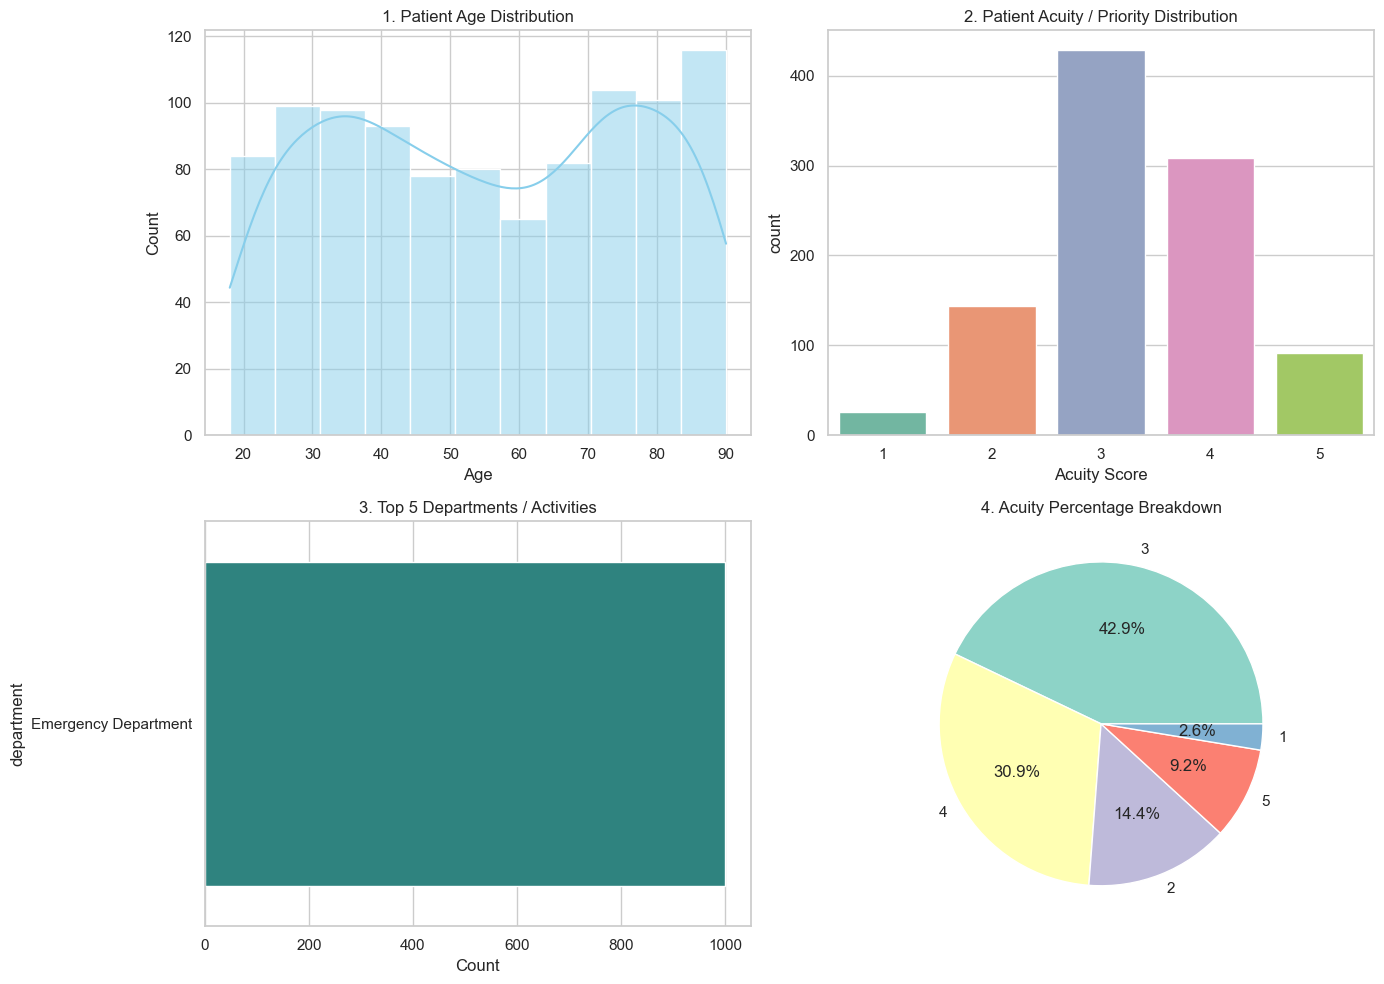

In [7]:
# Create a figure with subplots
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Patient Age Distribution
if "age" in df.columns or "Age" in df.columns:
    age_col = "age" if "age" in df.columns else "Age"
    sns.histplot(df[age_col], kde=True, ax=axes[0, 0], color="skyblue")
    axes[0, 0].set_title("1. Patient Age Distribution")
    axes[0, 0].set_xlabel("Age")

# 2. Acuity / Priority Level Breakdown
acuity_cols = [c for c in df.columns if c.lower() in ["acuity", "priority", "triage"]]
if acuity_cols:
    acuity_col = acuity_cols[0]
    sns.countplot(x=df[acuity_col], ax=axes[0, 1], palette="Set2")
    axes[0, 1].set_title("2. Patient Acuity / Priority Distribution")
    axes[0, 1].set_xlabel("Acuity Score")

# 3. Department / Activity Frequencies
dept_cols = [c for c in df.columns if c.lower() in ["department", "activity_name", "dept"]]
if dept_cols:
    dept_col = dept_cols[0]
    top_depts = df[dept_col].value_counts().head(5)
    sns.barplot(x=top_depts.values, y=top_depts.index, ax=axes[1, 0], palette="viridis")
    axes[1, 0].set_title("3. Top 5 Departments / Activities")
    axes[1, 0].set_xlabel("Count")

# 4. Gender / Categorical Distribution (if available)
gender_cols = [c for c in df.columns if "gender" in c.lower() or "sex" in c.lower()]
if gender_cols:
    sns.countplot(x=df[gender_cols[0]], ax=axes[1, 1], palette="Pastel1")
    axes[1, 1].set_title("4. Gender Distribution")
elif acuity_cols:
    df[acuity_cols[0]].value_counts().plot.pie(
        autopct="%1.1f%%", ax=axes[1, 1], colors=sns.color_palette("Set3")
    )
    axes[1, 1].set_title("4. Acuity Percentage Breakdown")
    axes[1, 1].set_ylabel("")

plt.tight_layout()
plt.show()


